# Marketing Lift and Experiment Lab

Aryan Kaushik | Personal analytics project

## 1. The question

Would I keep a campaign running if its extra conversions had to cover the cost?

I use three synthetic randomized experiments to work through the calculation, uncertainty and decision. The main campaign has a larger effect for returning customers in the generator. The small test may not give a clear answer. A deliberately broken extract shows why I check the data before using an apparent lift.

These are fictional campaigns generated with seed 89. The public Criteo download was unavailable from the build environment, so this version uses no Criteo records. None of the findings describe a real advertiser.


In [1]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt
from analysis import load_sources
from analysis import user_outcomes
from analysis import sql_outcomes
from analysis import data_checks
from analysis import experiment_quality
from analysis import filtered
from analysis import summarize
from analysis import select_development_groups
from analysis import economic_result
from analysis import decision
from analysis import planned_sample_size

ROOT = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
os.chdir(ROOT)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})

## 2. Read the assignment and purchase records

The assignment record determines the denominator. An event is a purchase, not a user. A user may have no events, several purchases or a re-delivered event.


In [2]:
raw, events, metadata = load_sources()
source_counts = pd.DataFrame({
    'source': ['Assignment deliveries', 'Purchase event deliveries'],
    'rows': [len(raw), len(events)],
    'repeated_ids': [raw.duplicated('user_id').sum(), events.duplicated('event_id').sum()]
})
print(source_counts.to_string(index=False))
print(raw.head(5).to_string(index=False))

                   source   rows  repeated_ids
    Assignment deliveries 118202            75
Purchase event deliveries   9570           105
experiment_id            user_id          assigned_at       arm customer_type  device       split  exposed
  retargeting retargeting_000000 2026-02-18T04:03:14Z Treatment     Returning Desktop  Evaluation        1
  retargeting retargeting_000001 2026-02-12T12:22:22Z Treatment           New  Mobile Development        1
  retargeting retargeting_000002 2026-02-06T00:35:36Z Treatment     Returning  Mobile Development        1
  retargeting retargeting_000003 2026-02-16T09:34:14Z Treatment     Returning Desktop  Evaluation        1
  retargeting retargeting_000004 2026-02-01T05:37:58Z Treatment           New  Mobile  Evaluation        1


## 3. Create one outcome per assigned user

I remove identical re-deliveries, then count purchases from assignment to just before seven days later. Two purchases still mean one converted user. A left join keeps assigned users with no purchase. All assignments have a complete observation window at the fixed extract date.


In [3]:
users = user_outcomes(raw, events, metadata['extract_at'])
print(users[['user_id', 'arm', 'exposed', 'purchases_in_window', 'converted']].head(8).to_string(index=False))
print('\nUnique assigned users:', len(users))
print('Assigned users with no qualifying purchase:', users['converted'].eq(0).sum())

           user_id       arm  exposed  purchases_in_window  converted
retargeting_000000 Treatment        1                    0          0
retargeting_000001 Treatment        1                    0          0
retargeting_000002 Treatment        1                    0          0
retargeting_000003 Treatment        1                    0          0
retargeting_000004 Treatment        1                    0          0
retargeting_000005 Treatment        1                    0          0
retargeting_000006   Control        0                    0          0
retargeting_000007   Control        0                    0          0

Unique assigned users: 118127
Assigned users with no qualifying purchase: 109416


## 4. Check the same calculation in SQL

The SQLite query uses the same assignment and event sources, with its own DISTINCT and time-window logic. I compare user IDs, purchase counts and conversion flags. These structural checks are separate from the experiment quality checks below.


In [4]:
sql_users = sql_outcomes(raw, events, metadata['extract_at'])
checks = data_checks(raw, events, users, sql_users, metadata['extract_at'])
print(checks.to_string(index=False))

                                      check  passed
                         Unique user output    True
     Assignment re-deliveries are identical    True
          Event re-deliveries are identical    True
   Every assignment has seven complete days    True
         SQL and pandas have the same users    True
      SQL and pandas conversion flags agree    True
       SQL and pandas purchase counts agree    True
Development and evaluation IDs are disjoint    True
            Conversions cannot exceed users    True
               No unknown experiment labels    True


## 5. Check allocation before interpreting outcomes

The configured treatment share is 50%. I compare the observed counts with that allocation using a chi-square sample-ratio check. A p-value below 0.001 blocks the experiment. I also check purchase users with no assignment. Passing an SRM check does not prove that the experiment is valid.


In [5]:
quality = experiment_quality(raw, events, users)
quality_table = pd.DataFrame(quality)
print(quality_table.to_string(index=False))

   experiment_id  assigned_users    srm_p  missing_assignment_event_users  blocked
missing_controls           13127 0.000000                             349     True
     retargeting          100000 0.349256                               0    False
      small_test            5000 0.269990                               0    False


The broken extract has 349 purchase users without an assignment and a large allocation mismatch. The generator deliberately removes some control assignments. I withhold its conversion recommendation. I do not fix this by filtering until a slice looks balanced.


## 6. Use evaluation users for the primary comparison

The development/evaluation split is independent of treatment and outcomes. Development contains about 40% of users. Evaluation contains about 60%. The primary estimate is the difference in seven-day conversion rates across all evaluation users in the main experiment. Treatment users stay in the analysis even if they never saw an ad.


           assigned_users  converted_users  conversion_rate
arm                                                        
Control             30282             2031         0.067070
Treatment           30003             2407         0.080225

Unexposed treatment users retained: 6584


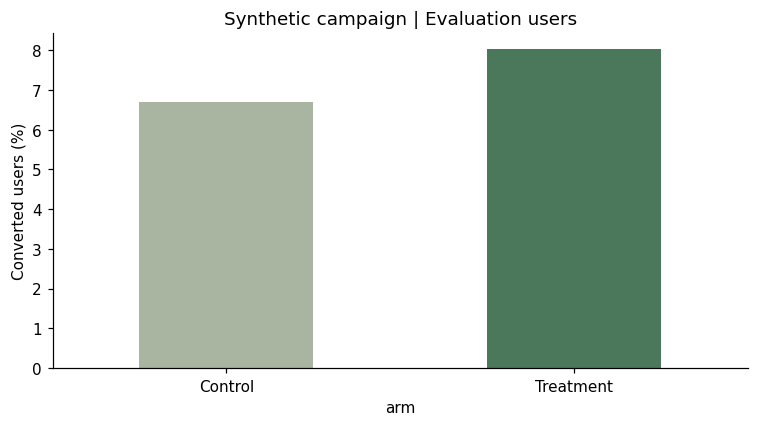

In [6]:
evaluation = filtered(users, 'retargeting', 'Evaluation')
rates = evaluation.groupby('arm')['converted'].agg(['size', 'sum', 'mean'])
rates.columns = ['assigned_users', 'converted_users', 'conversion_rate']
print(rates.to_string())
print('\nUnexposed treatment users retained:', evaluation.loc[evaluation['arm'].eq('Treatment'), 'exposed'].eq(0).sum())
rates['conversion_rate'].mul(100).plot.bar(color=['#a9b5a1', '#4b775b'], rot=0, figsize=(7, 4))
plt.ylabel('Converted users (%)')
plt.title('Synthetic campaign | Evaluation users')
plt.tight_layout()
plt.savefig(ROOT / 'outputs/evaluation_rates.png', dpi=120)

## 7. Put uncertainty around the lift

I calculate treatment rate minus control rate. The 95% interval uses Newcombe's combination of Wilson score intervals. This behaves better than a plain normal interval when a sample is small or has very few conversions. It assumes independent users and does not address interference between users.


                 n_t    n_c    effect     lower    upper
Main campaign  30003  30282  0.013156  0.008988 0.017329
Small test      1450   1541 -0.010896 -0.028347 0.006611


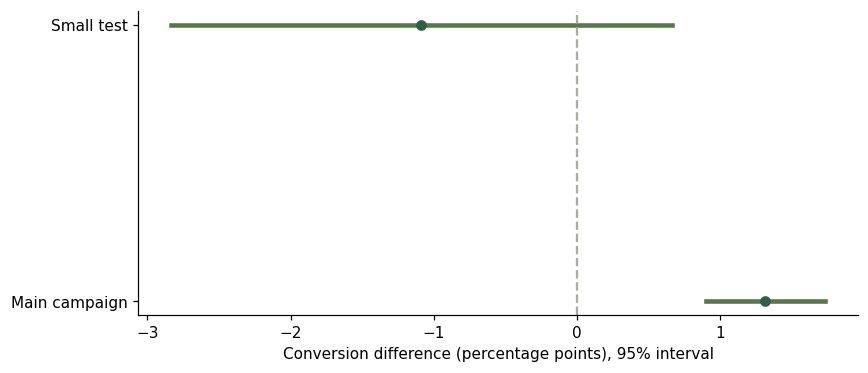

In [7]:
main_result = summarize(evaluation)
small_result = summarize(filtered(users, 'small_test', 'Evaluation'))
intervals = pd.DataFrame([main_result, small_result], index=['Main campaign', 'Small test'])
print(intervals[['n_t', 'n_c', 'effect', 'lower', 'upper']].to_string(float_format=lambda x: f'{x:.6f}'))
plt.figure(figsize=(8, 3.5))
for position, (label, row) in enumerate(intervals.iterrows()):
    plt.plot([row['lower'] * 100, row['upper'] * 100], [position, position], color='#56784b', linewidth=3)
    plt.scatter(row['effect'] * 100, position, color='#315e48', zorder=3)
plt.axvline(0, color='#a8aea2', linestyle='--')
plt.yticks([0, 1], intervals.index)
plt.xlabel('Conversion difference (percentage points), 95% interval')
plt.tight_layout()
plt.savefig(ROOT / 'outputs/evaluation_intervals.png', dpi=120)

The main result is +1.32 percentage points, with a 95% interval from +0.90 to +1.73. The small test is -1.09 points, with an interval from -2.83 to +0.66. That small-test interval includes zero. It does not establish that the campaign has no effect.


## 8. Choose a customer group using development only

I compare two predefined customer types in development and keep the one with the larger lower interval bound. Then I inspect that fixed group in evaluation. The selection code never reads evaluation outcomes. This is a secondary check beside the overall primary result, with no family-wise multiplicity claim. The other segment and device views remain exploratory.


In [8]:
chosen = select_development_groups(users)
chosen_group = chosen['retargeting']
group_result = summarize(filtered(users, 'retargeting', 'Evaluation', chosen_group))
print('Development selected:', chosen_group)
print(pd.DataFrame([group_result], index=['Fixed group in evaluation']).to_string())

Development selected: Returning
                             n_t    n_c   y_t   y_c    effect     lower     upper     srm_p
Fixed group in evaluation  12033  12209  1610  1318  0.025846  0.017644  0.034055  0.258312


Development chooses returning customers. Their evaluation lift is +2.58 points, with a 95% interval of +1.76 to +3.41. I have not run a formal interaction test to establish a difference from new customers. Separate group intervals alone do not establish that difference.


## 9. Check whether the extra conversions cover the cost

I assume CAD 90 contribution per extra conversion and CAD 0.60 cost per assigned treatment user. These amounts are hypothetical. Net contribution per 1,000 treated is 1,000 × (conversion difference × contribution per conversion - cost per treated user). The interval holds both money inputs fixed.


In [9]:
cost_rows = []
for cost in [0.3, 0.6, 1.6, 5.0]:
    net = economic_result(main_result, cost, contribution=90)
    cost_rows.append({'cost_per_treated': cost, **net,
                      'decision': decision(main_result, quality_table.set_index('experiment_id').loc['retargeting', 'srm_p'], cost=cost)})
print(pd.DataFrame(cost_rows).to_string(index=False, float_format=lambda x: f'{x:,.2f}'))

 cost_per_treated     point     lower     upper                    decision
             0.30    884.02    508.88  1,259.61   Worth a follow-up rollout
             0.60    584.02    208.88    959.61   Worth a follow-up rollout
             1.60   -415.98   -791.12    -40.39 Does not cover assumed cost
             5.00 -3,815.98 -4,191.12 -3,440.39 Does not cover assumed cost


At the default assumptions, the main campaign has estimated net contribution of CAD 584 per 1,000 treated users, with an interval from CAD 209 to CAD 960. It supports a follow-up rollout within this scenario. It does not show realized profit or guarantee the same result at a larger scale.


## 10. Preserve an inconclusive answer

The small test does not establish a conversion effect. At the default cost its upper net bound is only just below zero. At CAD 0.30 per treated user, the net interval crosses zero and the economic decision is inconclusive. This is a sensitivity example, not a reason to pick a convenient cost.


In [10]:
small_cost_rows = []
for cost in [0.3, 0.6]:
    small_cost_rows.append({'cost': cost, **economic_result(small_result, cost, 90),
                           'decision': decision(small_result, quality_table.set_index('experiment_id').loc['small_test', 'srm_p'], cost=cost)})
print(pd.DataFrame(small_cost_rows).to_string(index=False, float_format=lambda x: f'{x:,.2f}'))

 cost     point     lower  upper                    decision
 0.30 -1,280.66 -2,851.24 295.01   Inconclusive at this cost
 0.60 -1,580.66 -3,151.24  -4.99 Does not cover assumed cost


## 11. Plan a new fixed-horizon test

I use the standard normal approximation for two independent conversion rates, equal group sizes, 80% power and a two-sided 5% test. The baseline and target increase are planning assumptions, not post-hoc power for the current result. A smaller useful effect needs more data.


In [11]:
planning = pd.DataFrame({
    'baseline': [0.07, 0.07, 0.07],
    'absolute_increase': [0.005, 0.01, 0.02]
})
planning['users_per_arm'] = [planned_sample_size(p, d) for p, d in zip(planning['baseline'], planning['absolute_increase'])]
print(planning.to_string(index=False))

 baseline  absolute_increase  users_per_arm
     0.07              0.005          42222
     0.07              0.010          10890
     0.07              0.020           2888


## 12. What I would take to a campaign lead

The main synthetic campaign passes the allocation and record checks. The evaluation result supports a positive incremental conversion effect. At the default cost assumptions, its net interval is above zero. I would use this as a reason for a measured follow-up rollout, keeping the same outcome definition and watching cost and customer mix.

The small test needs a careful answer. Its conversion interval includes both harm and benefit. Its economic interpretation depends on the cost assumption. I would not call it a no-effect result.

The missing-controls experiment needs a data fix before a campaign recommendation. The denominator is unreliable. A convincing-looking conversion difference would not solve that problem.

All results here come from synthetic data. There are no real advertising costs, revenue records or live platform integrations. The project does not model clustering, cross-user interference, repeat experimentation, contribution uncertainty or long-term customer value. The Criteo public benchmark is a deferred extension, not a completed data integration.

The dashboard is in dist/index.html. The README and docs/walkthrough.md explain how to run it, use each control and trace a user. This notebook was executed from a fresh Python namespace by tools/make_notebook.py. It was not run through an external Jupyter kernel.
